# 04 · Análisis, pronóstico y alerta (R4 · R5 · Hito 3)
**Proyecto semestral · Sala de crisis COVID-19 · Gestión de Datos IN1232C · 2026-2**

Requiere `03_dw_estrella` (lee el Data Warehouse `covid_dw.db`).

1. Armar la **serie territorio × día** (países y regiones de Chile) desde el DW.
2. `alerta(territorio, fecha)`: alerta temprana con umbral calibrado en la historia de Chile.
3. `pronosticar(territorio, fecha_corte, horizonte=14)`: tres modelos, evaluados con MAE y MAPE en seis fechas de corte.
4. Respuestas a P1, P2, P4 y P6.
5. Guardar la serie para el tablero (Streamlit).

**Regla de oro del desafío en vivo:** `alerta()` y `pronosticar()` solo miran datos **hasta la fecha de corte**.

## Setup

In [1]:
import os
import shutil
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 2)

from google.colab import drive
drive.mount('/content/drive')

PROYECTO = '/content/drive/MyDrive/proyecto-gestion-datos-2026'
LIMPIOS = os.path.join(PROYECTO, 'data', 'clean')

# Copiamos el DW al disco de la sesión: las consultas son más rápidas
shutil.copy(os.path.join(PROYECTO, 'data', 'dw', 'covid_dw.db'), '/content/covid_dw.db')
dw = sqlite3.connect('/content/covid_dw.db')

## 1 · Serie territorio × día

Desde el DW sumamos los **acumulados** por país (y por región, para Chile) en cada día. Los nuevos se calculan como la diferencia del acumulado con el día anterior.

- Se **excluye el archivo defectuoso del 23-may-2022** (decisión de `02_calidad`): si no, aparece una caída y un rebote falsos en 136 países.
- Si el acumulado baja (corrección), el nuevo queda negativo; para las medias móviles se usa 0 ese día (no se inventa el reparto).
- Las entidades especiales (cruceros, JJ.OO., Antártica) no entran.

In [2]:
paises = pd.read_sql("""
    SELECT t.pais AS territorio, t.pais, 'pais' AS nivel, d.fecha,
           SUM(f.casos_acum) AS casos_acum, SUM(f.fallecidos_acum) AS fallecidos_acum
    FROM fact_covid f
    JOIN dim_fecha d      ON d.fecha_key = f.fecha_key
    JOIN dim_territorio t ON t.territorio_key = f.territorio_key
    WHERE f.archivo_defectuoso = 0
    GROUP BY t.pais, d.fecha
""", dw)

regiones = pd.read_sql("""
    SELECT 'Chile · ' || t.region AS territorio, t.pais, 'region' AS nivel, d.fecha,
           SUM(f.casos_acum) AS casos_acum, SUM(f.fallecidos_acum) AS fallecidos_acum
    FROM fact_covid f
    JOIN dim_fecha d      ON d.fecha_key = f.fecha_key
    JOIN dim_territorio t ON t.territorio_key = f.territorio_key
    WHERE f.archivo_defectuoso = 0 AND t.pais = 'Chile' AND t.nivel = 'region' AND t.region <> 'Unknown'
    GROUP BY t.region, d.fecha
""", dw)

# Población y coordenadas: fila del país (o de la región) en la dimensión territorio
dim = pd.read_sql('SELECT * FROM dim_territorio WHERE en_tabla_uid = 1', dw)
pob_pais = dim[dim['nivel'] == 'pais'][['pais', 'poblacion', 'lat', 'long', 'iso3']]
pob_pais = pob_pais.rename(columns={'pais': 'territorio'})
pob_region = dim[(dim['pais'] == 'Chile') & (dim['nivel'] == 'region')][['region', 'poblacion', 'lat', 'long', 'iso3']]
pob_region['territorio'] = 'Chile · ' + pob_region['region']
pob_region = pob_region.drop(columns='region')

serie = pd.concat([paises.merge(pob_pais, on='territorio'),
                   regiones.merge(pob_region, on='territorio')], ignore_index=True)

entidades_especiales = ['Diamond Princess', 'MS Zaandam', 'Summer Olympics 2020', 'Winter Olympics 2022', 'Antarctica']
serie = serie[~serie['territorio'].isin(entidades_especiales) & (serie['poblacion'] > 0)]

serie['fecha'] = pd.to_datetime(serie['fecha'])
serie = serie.sort_values(['territorio', 'fecha']).reset_index(drop=True)
serie['casos_nuevos'] = serie.groupby('territorio')['casos_acum'].diff()
serie['fallecidos_nuevos'] = serie.groupby('territorio')['fallecidos_acum'].diff()

# Media móvil de 7 días (días negativos = 0) e incidencia de 7 días por 100.000 habitantes
serie['casos_mm7'] = serie.groupby('territorio')['casos_nuevos'].transform(lambda s: s.clip(lower=0).rolling(7).mean())
serie['fallecidos_mm7'] = serie.groupby('territorio')['fallecidos_nuevos'].transform(lambda s: s.clip(lower=0).rolling(7).mean())
serie['incidencia_7d'] = serie['casos_mm7'] * 7 / serie['poblacion'] * 100000

print(f"{len(serie):,} filas · {serie[serie['nivel'] == 'pais']['territorio'].nunique()} países · "
      f"{serie[serie['nivel'] == 'region']['territorio'].nunique()} regiones de Chile")
serie[serie['territorio'] == 'Chile'].tail()

231,134 filas · 196 países · 16 regiones de Chile


,territorio,pais,nivel,fecha,casos_acum,fallecidos_acum,poblacion,lat,long,iso3,casos_nuevos,fallecidos_nuevos,casos_mm7,fallecidos_mm7,incidencia_7d
39562,Chile,Chile,pais,2023-03-05,5.18e+06,64230.0,1.91e+07,-35.68,-71.54,CHL,2559.0,8.0,2430.43,9.14,89.00
39563,Chile,Chile,pais,2023-03-06,5.18e+06,64247.0,1.91e+07,-35.68,-71.54,CHL,2031.0,17.0,2491.14,10.43,91.22
39564,Chile,Chile,pais,2023-03-07,5.18e+06,64250.0,1.91e+07,-35.68,-71.54,CHL,2222.0,3.0,2607.71,10.71,95.49
39565,Chile,Chile,pais,2023-03-08,5.19e+06,64254.0,1.91e+07,-35.68,-71.54,CHL,3798.0,4.0,2748.71,11.00,100.65
39566,Chile,Chile,pais,2023-03-09,5.19e+06,64273.0,1.91e+07,-35.68,-71.54,CHL,3906.0,19.0,2885.14,10.86,105.65


## 2 · Alerta temprana

### 2.1 · Las olas de Chile
**Ola:** período en que la incidencia de 7 días supera **100 por 100.000** durante al menos 14 días (si baja menos de 14 días y vuelve a subir, es la misma ola). Sirve para evaluar la alerta: una buena alerta se enciende **antes** de que empiece cada ola.

In [3]:
def olas(territorio, nivel=100, min_dias=14):
    s = serie[serie['territorio'] == territorio].set_index('fecha')['incidencia_7d']
    sobre = s > nivel
    # cada vez que cambia de "bajo" a "sobre" empieza un tramo
    tramo = (sobre != sobre.shift()).cumsum()
    tramos = s[sobre].groupby(tramo[sobre]).agg(inicio=lambda x: x.index.min(), fin=lambda x: x.index.max())
    # unir tramos separados por menos de min_dias
    lista = []
    for _, t in tramos.iterrows():
        if lista and (t['inicio'] - lista[-1]['fin']).days < min_dias:
            lista[-1]['fin'] = t['fin']
        else:
            lista.append({'inicio': t['inicio'], 'fin': t['fin']})
    res = pd.DataFrame(lista)
    res = res[(res['fin'] - res['inicio']).dt.days + 1 >= min_dias].reset_index(drop=True)
    res['dias'] = (res['fin'] - res['inicio']).dt.days + 1
    res['peak_incidencia_7d'] = [round(s[i:f].max()) for i, f in zip(res['inicio'], res['fin'])]
    res['fecha_peak'] = [s[i:f].idxmax().date() for i, f in zip(res['inicio'], res['fin'])]
    res.index = [f'Ola {k + 1}' for k in range(len(res))]
    return res

olas_chile = olas('Chile')
olas_chile

,inicio,fin,dias,peak_incidencia_7d,fecha_peak
Ola 1,2020-05-20,2020-07-12,54,378,2020-06-17
Ola 2,2021-01-07,2021-07-09,184,268,2021-04-14
Ola 3,2022-01-09,2022-04-16,98,1306,2022-02-13
Ola 4,2022-05-10,2023-01-17,253,386,2022-06-17


### 2.2 · Indicador y calibración del umbral
**Indicador:** incidencia de los últimos 7 días por 100.000 habitantes, comparada con la de los 7 días anteriores. La alerta se enciende si la incidencia **sube más de X %** en una semana **y** ya supera **Y casos por 100.000** (para no alertar por subidas de 2 a 4 casos).

Para elegir X e Y probamos varias combinaciones en la historia de Chile. `historia_alerta()` calcula el indicador para todos los días a la vez con `rolling(7)` y `shift(7)`: cada día usa **solo** los 14 días anteriores, igual que `alerta()`.

**Criterio:** detectar **todas** las olas con el **menor número de falsas alarmas** (una falsa alarma es un episodio de alerta que no termina en una ola dentro de 30 días).

In [4]:
def historia_alerta(territorio, umbral_variacion, umbral_minimo):
    s = serie[serie['territorio'] == territorio].set_index('fecha')
    nuevos = s['casos_nuevos'].clip(lower=0)
    inc = nuevos.rolling(7).sum() / s['poblacion'] * 100000      # últimos 7 días
    inc_anterior = inc.shift(7)                                    # los 7 días anteriores
    variacion = (inc / inc_anterior.where(inc_anterior > 0) - 1) * 100
    activa = (variacion > umbral_variacion) & (inc >= umbral_minimo)
    return activa[activa.index >= '2020-03-20']


def evaluar_alerta(activa, olas_df, ventana=30):
    # Anticipación: días entre la primera alerta (en los 30 días previos) y el inicio de cada ola
    anticipacion = []
    for _, ola in olas_df.iterrows():
        previa = activa[(activa.index >= ola['inicio'] - pd.Timedelta(days=ventana)) & (activa.index <= ola['inicio'])]
        anticipacion.append((ola['inicio'] - previa[previa].index.min()).days if previa.any() else np.nan)
    # Episodios: días seguidos con alerta; falsa alarma si no termina en una ola dentro de 30 días
    episodio = (activa != activa.shift()).cumsum()
    inicios = activa[activa].groupby(episodio[activa]).apply(lambda x: x.index.min())
    falsas = 0
    for inicio in inicios:
        cerca = [(inicio <= ola['fin']) and (ola['inicio'] - inicio <= pd.Timedelta(days=ventana))
                 for _, ola in olas_df.iterrows()]
        if not any(cerca):
            falsas += 1
    return anticipacion, len(inicios), falsas


filas = []
for umbral_variacion in [20, 30, 40, 50, 75]:
    for umbral_minimo in [10, 20, 40]:
        activa = historia_alerta('Chile', umbral_variacion, umbral_minimo)
        anticipacion, episodios, falsas = evaluar_alerta(activa, olas_chile)
        filas.append({'umbral_variacion': umbral_variacion, 'umbral_minimo': umbral_minimo,
                      'olas_detectadas': int(np.sum(~np.isnan(anticipacion))),
                      'anticipacion_dias': anticipacion, 'episodios': episodios, 'falsas_alarmas': falsas})
calibracion = pd.DataFrame(filas)
calibracion

,umbral_variacion,umbral_minimo,olas_detectadas,anticipacion_dias,episodios,falsas_alarmas
0,20,10,4,"[22, 20, 6, 3]",29,8
1,20,20,4,"[20, 20, 6, 3]",27,7
2,20,40,4,"[15, 20, 6, 3]",26,6
3,30,10,4,"[20, 3, 5, 0]",16,5
4,30,20,4,"[20, 3, 5, 0]",15,4
5,30,40,4,"[15, 3, 5, 0]",14,3
6,40,10,2,"[20, nan, 3, nan]",13,3
7,40,20,2,"[20, nan, 3, nan]",12,2
8,40,40,2,"[15, nan, 3, nan]",11,1
9,50,10,2,"[19, nan, 2, nan]",11,2


In [5]:
# Elegir: todas las olas detectadas, menos falsas alarmas y, si empatan, más anticipación promedio
calibracion['anticipacion_media'] = calibracion['anticipacion_dias'].apply(np.nanmean)
candidatas = calibracion[calibracion['olas_detectadas'] == len(olas_chile)]
mejor = candidatas.sort_values(['falsas_alarmas', 'anticipacion_media'], ascending=[True, False]).iloc[0]
UMBRAL_VARIACION = int(mejor['umbral_variacion'])   # % de alza semanal
UMBRAL_MINIMO = int(mejor['umbral_minimo'])         # casos por 100.000 en 7 días
print(f'Umbral elegido: alza > {UMBRAL_VARIACION} % en una semana y al menos {UMBRAL_MINIMO} casos por 100.000')
print('Anticipación por ola (días):', mejor['anticipacion_dias'], '| falsas alarmas:', mejor['falsas_alarmas'],
      'de', mejor['episodios'], 'episodios')

Umbral elegido: alza > 30 % en una semana y al menos 40 casos por 100.000
Anticipación por ola (días): [15, 3, 5, 0] | falsas alarmas: 3 de 14 episodios


### 2.3 · La función `alerta(territorio, fecha)`
Es la que se usa en el **desafío en vivo**: recibe la fecha como parámetro y **solo mira datos hasta esa fecha**.

In [6]:
def alerta(territorio, fecha):
    fecha = pd.Timestamp(fecha)
    s = serie[(serie['territorio'] == territorio) & (serie['fecha'] <= fecha)]   # solo el pasado
    nuevos = s['casos_nuevos'].clip(lower=0)
    pob = s['poblacion'].iloc[0]
    inc_actual = nuevos.tail(7).sum() / pob * 100000
    inc_anterior = nuevos.iloc[-14:-7].sum() / pob * 100000
    if inc_anterior > 0:
        variacion = (inc_actual / inc_anterior - 1) * 100
    else:
        variacion = np.nan
    activa = (variacion > UMBRAL_VARIACION) and (inc_actual >= UMBRAL_MINIMO)
    return {'territorio': territorio, 'fecha': fecha.date(), 'incidencia_7d': round(inc_actual, 1),
            'incidencia_semana_anterior': round(inc_anterior, 1), 'variacion_%': round(variacion, 1),
            'alerta': 'ACTIVA' if activa else 'no'}

# Comprobación: alerta() y historia_alerta() dan lo mismo
historia = historia_alerta('Chile', UMBRAL_VARIACION, UMBRAL_MINIMO)
for f in ['2020-05-10', '2021-12-27', '2022-01-05', '2022-06-01']:
    assert (alerta('Chile', f)['alerta'] == 'ACTIVA') == historia[f]
alerta('Chile', '2022-01-05')

{'territorio': 'Chile',
 'fecha': datetime.date(2022, 1, 5),
 'incidencia_7d': np.float64(59.1),
 'incidencia_semana_anterior': np.float64(42.6),
 'variacion_%': np.float64(38.8),
 'alerta': 'ACTIVA'}

In [7]:
anticipacion, episodios, falsas = evaluar_alerta(historia, olas_chile)
tabla_alerta = olas_chile[['inicio', 'fin', 'peak_incidencia_7d']].copy()
tabla_alerta['dias_de_anticipacion'] = anticipacion
print('Episodios de alerta:', episodios, '| falsas alarmas:', falsas)
tabla_alerta

Episodios de alerta: 14 | falsas alarmas: 3


,inicio,fin,peak_incidencia_7d,dias_de_anticipacion
Ola 1,2020-05-20,2020-07-12,378,15
Ola 2,2021-01-07,2021-07-09,268,3
Ola 3,2022-01-09,2022-04-16,1306,5
Ola 4,2022-05-10,2023-01-17,386,0


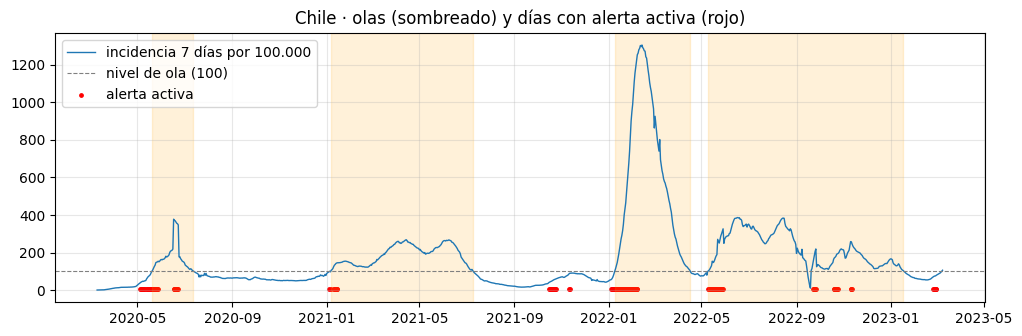

In [8]:
chile = serie[serie['territorio'] == 'Chile']
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(chile['fecha'], chile['incidencia_7d'], linewidth=1, label='incidencia 7 días por 100.000')
ax.axhline(100, color='gray', linestyle='--', linewidth=0.8, label='nivel de ola (100)')
dias_alerta = historia[historia].index
ax.scatter(dias_alerta, [5] * len(dias_alerta), color='red', s=6, label='alerta activa')
for nombre, ola in olas_chile.iterrows():
    ax.axvspan(ola['inicio'], ola['fin'], color='orange', alpha=0.15)
ax.set_title('Chile · olas (sombreado) y días con alerta activa (rojo)')
ax.legend(loc='upper left')
ax.grid(alpha=0.3)
plt.show()

**Interpretación:** con un alza de **más de 30 % semanal** y al menos **40 casos por 100.000**, la alerta detecta **las 4 olas** de Chile: la primera con **15 días** de anticipación, ómicron con **5**, la segunda con 3 y la cuarta el mismo día en que empieza. Da **3 falsas alarmas** en 14 episodios. Umbrales más exigentes (50 %) dan menos falsas alarmas, pero no detectan las olas que suben lento (2 y 4).

## 3 · Pronóstico

`pronosticar(territorio, fecha_corte, horizonte=14)` pronostica los **casos nuevos diarios (media móvil de 7 días)** de los próximos `horizonte` días, usando **solo datos hasta `fecha_corte`**. Compara **tres modelos**:

| Modelo | Idea |
|---|---|
| **Media móvil** (base) | Los próximos días serán iguales al promedio de la última semana |
| **Tendencia** | Recta ajustada (`np.polyfit`) al logaritmo de la media móvil de las últimas 2 semanas: si los casos venían creciendo un x % diario, siguen igual |
| **Crecimiento semanal** | Si esta semana hubo r veces los casos de la anterior, la próxima también crece r veces (r limitado entre 0,5 y 2 para no extrapolar explosiones) |

`comparar()` pone al lado lo que **realmente pasó** y calcula MAE y MAPE.

In [9]:
def pronosticar(territorio, fecha_corte, horizonte=14):
    fecha_corte = pd.Timestamp(fecha_corte)
    s = serie[(serie['territorio'] == territorio) & (serie['fecha'] <= fecha_corte)]   # solo el pasado
    mm7 = s['casos_mm7'].dropna()
    dias = np.arange(1, horizonte + 1)

    # 1. Media móvil: repetir el último promedio de 7 días
    media_movil = np.repeat(mm7.iloc[-1], horizonte)

    # 2. Tendencia: recta sobre el log de las últimas 14 medias móviles
    y = np.log(mm7.tail(14).clip(lower=1))
    x = np.arange(len(y))
    pendiente, intercepto = np.polyfit(x, y, 1)
    tendencia = np.exp(intercepto + pendiente * (len(y) - 1 + dias))

    # 3. Crecimiento semanal: razón entre esta semana y la anterior, limitada a [0,5 ; 2]
    r = np.clip(mm7.iloc[-1] / max(mm7.iloc[-8], 1), 0.5, 2.0)
    crecimiento = mm7.iloc[-1] * r ** (dias / 7)

    fechas = pd.date_range(fecha_corte + pd.Timedelta(days=1), periods=horizonte)
    return pd.DataFrame({'fecha': fechas, 'media_movil': np.round(media_movil),
                         'tendencia': np.round(tendencia), 'crecimiento_semanal': np.round(crecimiento)})


MODELOS = ['media_movil', 'tendencia', 'crecimiento_semanal']

def comparar(territorio, fecha_corte, horizonte=14):
    p = pronosticar(territorio, fecha_corte, horizonte)
    real = serie[serie['territorio'] == territorio][['fecha', 'casos_mm7']].rename(columns={'casos_mm7': 'real'})
    p = p.merge(real, on='fecha', how='left')
    errores = {}
    for modelo in MODELOS:
        error = (p[modelo] - p['real']).abs()
        errores[modelo] = {'MAE': round(error.mean()), 'MAPE %': round((error / p['real'].clip(lower=1)).mean() * 100, 1)}
    return p, pd.DataFrame(errores).T

pronosticar('Chile', '2021-12-27')

,fecha,media_movil,tendencia,crecimiento_semanal
0,2021-12-28,1162.0,1148.0,1150.0
1,2021-12-29,1162.0,1131.0,1138.0
2,2021-12-30,1162.0,1114.0,1126.0
3,2021-12-31,1162.0,1097.0,1115.0
4,2022-01-01,1162.0,1081.0,1103.0
5,2022-01-02,1162.0,1065.0,1092.0
6,2022-01-03,1162.0,1049.0,1081.0
7,2022-01-04,1162.0,1034.0,1070.0
8,2022-01-05,1162.0,1019.0,1059.0
9,2022-01-06,1162.0,1003.0,1048.0


In [10]:
# Backtesting: seis fechas de corte en Chile, en distintos momentos de las olas
cortes = ['2020-06-01', '2021-03-15', '2021-06-15', '2021-12-27', '2022-02-15', '2022-06-01']
filas = []
for corte in cortes:
    _, err = comparar('Chile', corte)
    for modelo, fila in err.iterrows():
        filas.append({'fecha_corte': corte, 'modelo': modelo, 'MAE': fila['MAE'], 'MAPE %': fila['MAPE %']})
backtest = pd.DataFrame(filas)
backtest.pivot_table(index='fecha_corte', columns='modelo', values='MAPE %')[MODELOS]

modelo,media_movil,tendencia,crecimiento_semanal
fecha_corte,,,
2020-06-01,10.3,31.3,3.3
2021-03-15,13.6,3.7,1.5
2021-06-15,30.4,29.4,18.0
2021-12-27,26.4,32.6,30.9
2022-02-15,16.6,37.2,19.1
2022-06-01,14.7,39.7,11.6


In [11]:
backtest.groupby('modelo')[['MAE', 'MAPE %']].mean().loc[MODELOS].round(1)

,MAE,MAPE %
modelo,,
media_movil,1573.2,18.7
tendencia,3025.2,29.0
crecimiento_semanal,1371.3,14.1


**Interpretación:** en promedio gana el **crecimiento semanal** (menor MAPE), pero ningún modelo gana siempre. Cuando la curva **cambia de dirección** (peak o inicio de ola), los modelos de tendencia y crecimiento se equivocan más porque siguen la dirección anterior; cuando la curva **sigue subiendo**, la media móvil se queda corta. Por eso el tablero muestra los tres.

## 4 · Respuestas
### P1 · ¿Cómo vivió Chile la pandemia comparado con el resto de Sudamérica?

In [12]:
sudamerica = ['Argentina', 'Bolivia', 'Brazil', 'Chile', 'Colombia', 'Ecuador', 'Guyana',
              'Paraguay', 'Peru', 'Suriname', 'Uruguay', 'Venezuela']
ultimo = serie[(serie['fecha'] == serie['fecha'].max()) & serie['territorio'].isin(sudamerica)].copy()
ultimo['casos_x100k'] = (ultimo['casos_acum'] / ultimo['poblacion'] * 100000).round(0)
ultimo['fallecidos_x100k'] = (ultimo['fallecidos_acum'] / ultimo['poblacion'] * 100000).round(1)
p1 = ultimo.sort_values('fallecidos_x100k', ascending=False)[['territorio', 'casos_x100k', 'fallecidos_x100k']]
p1['posicion_fallecidos'] = range(1, len(p1) + 1)
p1

,territorio,casos_x100k,fallecidos_x100k,posicion_fallecidos
168750,Peru,13610.0,665.8,1
39566,Chile,27162.0,336.2,2
26399,Brazil,17443.0,329.0,3
7689,Argentina,22225.0,288.7,4
58175,Colombia,12498.0,279.7,5
167652,Paraguay,11334.0,278.7,6
200421,Suriname,14058.0,239.3,7
222641,Uruguay,29775.0,219.3,8
73470,Ecuador,5992.0,204.1,9
23118,Bolivia,10231.0,191.6,10


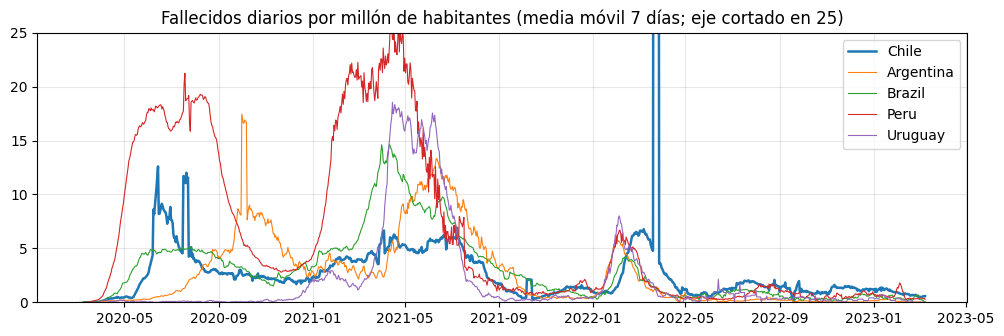

Días con carga de rezago en fallecidos:
     fecha  fallecidos_nuevos
2020-06-08              627.0
2020-07-17             1057.0
2022-03-21            11447.0

Ola con más casos: Ola 3 | ola con más fallecidos (sin cargas de rezago): Ola 2


,inicio,fin,dias,peak_incidencia_7d,fecha_peak,casos,fallecidos,fallecidos_sin_cargas
Ola 1,2020-05-20,2020-07-12,54,378,2020-06-17,2.65e+05,6470.0,5843.0
Ola 2,2021-01-07,2021-07-09,184,268,2021-04-14,9.57e+05,16820.0,16820.0
Ola 3,2022-01-09,2022-04-16,98,1306,2022-02-13,1.70e+06,17980.0,6533.0
Ola 4,2022-05-10,2023-01-17,253,386,2022-06-17,1.51e+06,5909.0,5909.0


In [13]:
fig, ax = plt.subplots(figsize=(12, 3.5))
for pais in ['Chile', 'Argentina', 'Brazil', 'Peru', 'Uruguay']:
    s = serie[serie['territorio'] == pais]
    fall = s['fallecidos_mm7'] / s['poblacion'] * 1000000
    ax.plot(s['fecha'], fall, linewidth=1.8 if pais == 'Chile' else 0.8, label=pais)
ax.set_ylim(0, 25)   # Perú sumó de una vez ~110 mil fallecidos reclasificados (jun-2021): ese salto queda fuera del eje
ax.set_title('Fallecidos diarios por millón de habitantes (media móvil 7 días; eje cortado en 25)')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Las olas de Chile: cuándo empezaron y terminaron, y cuántos casos y fallecidos dejó cada una
chile = serie[serie['territorio'] == 'Chile'].copy()

# Cargas de rezago en fallecidos (misma idea que la regla de 02_calidad para casos):
# un día con más de 5 veces la media de la semana anterior y más de 500 fallecidos no son muertes de ese día
media_previa = chile['fallecidos_nuevos'].rolling(7).mean().shift(1)
chile['carga_rezago'] = (chile['fallecidos_nuevos'] > 5 * media_previa) & (chile['fallecidos_nuevos'] > 500)
print('Días con carga de rezago en fallecidos:')
print(chile.loc[chile['carga_rezago'], ['fecha', 'fallecidos_nuevos']].to_string(index=False))

olas_p1 = olas_chile[['inicio', 'fin', 'dias', 'peak_incidencia_7d', 'fecha_peak']].copy()
olas_p1['casos'] = [chile[(chile['fecha'] >= i) & (chile['fecha'] <= f)]['casos_nuevos'].sum()
                    for i, f in zip(olas_p1['inicio'], olas_p1['fin'])]
olas_p1['fallecidos'] = [chile[(chile['fecha'] >= i) & (chile['fecha'] <= f)]['fallecidos_nuevos'].sum()
                         for i, f in zip(olas_p1['inicio'], olas_p1['fin'])]
olas_p1['fallecidos_sin_cargas'] = [chile[(chile['fecha'] >= i) & (chile['fecha'] <= f) & ~chile['carga_rezago']]['fallecidos_nuevos'].sum()
                                    for i, f in zip(olas_p1['inicio'], olas_p1['fin'])]
print('\nOla con más casos:', olas_p1['casos'].idxmax(),
      '| ola con más fallecidos (sin cargas de rezago):', olas_p1['fallecidos_sin_cargas'].idxmax())
olas_p1

**Interpretación:** Chile es **2.º de Sudamérica en fallecidos por 100.000 (336)**, detrás de Perú (666) y apenas sobre Brasil (329); en casos por 100.000 también es 2.º (27.162), detrás de Uruguay, lo que refleja en parte cuánto testeó. Tuvo **4 olas**: may–jul 2020, ene–jul 2021, ene–abr 2022 y may 2022–ene 2023. La de **más casos fue ómicron (ola 3)**: 1,7 millones, con un peak de 1.306 por 100.000 en 7 días el 13-feb-2022. La de **más fallecidos fue la ola de 2021 (ola 2)**: unos 16.800. Ojo: el 21-mar-2022, en plena ola 3, el reporte de Chile sumó de una vez **11.447 fallecidos** (una carga de rezago, no muertes de ese día); contándola, la ola 3 parecería la más mortal (18 mil), pero sin ella deja unos 6.500.

### P2 · ¿Qué regiones de Chile fueron más golpeadas y en qué ola?
Desde el 1-jun-2020 (Chile informa por región desde el 20-may-2020).

In [14]:
reg = serie[(serie['nivel'] == 'region') & (serie['fecha'] >= '2020-06-01')].copy()
p2 = reg.groupby('territorio').agg(casos=('casos_nuevos', 'sum'), fallecidos=('fallecidos_nuevos', 'sum'),
                                   poblacion=('poblacion', 'first'), lat=('lat', 'first'), long=('long', 'first'))
p2['casos_x100k'] = (p2['casos'] / p2['poblacion'] * 100000).round(0)
p2['fallecidos_x100k'] = (p2['fallecidos'] / p2['poblacion'] * 100000).round(1)
p2 = p2.sort_values('fallecidos_x100k', ascending=False)
p2['posicion'] = range(1, len(p2) + 1)
print('Biobío:', p2.loc['Chile · Biobio', 'posicion'], 'de', len(p2), 'en fallecidos por 100.000')
p2[['casos_x100k', 'fallecidos_x100k', 'posicion']]

Biobío: 10 de 16 en fallecidos por 100.000


,casos_x100k,fallecidos_x100k,posicion
territorio,,,
Chile · Magallanes,39990.0,453.4,1
Chile · Metropolitana,26528.0,423.1,2
Chile · Arica y Parinacota,34989.0,395.0,3
Chile · Los Rios,38431.0,365.1,4
Chile · Valparaiso,26970.0,352.2,5
Chile · Tarapaca,33634.0,348.5,6
Chile · Maule,33064.0,319.5,7
Chile · Antofagasta,29842.0,317.7,8
Chile · Los Lagos,29226.0,309.4,9


In [15]:
# ¿En qué ola? Casos por 100.000 de cada región en cada ola de Chile
filas = []
for nombre, ola in olas_chile.iterrows():
    tramo = reg[(reg['fecha'] >= ola['inicio']) & (reg['fecha'] <= ola['fin'])]
    t = tramo.groupby('territorio').agg(casos=('casos_nuevos', 'sum'), poblacion=('poblacion', 'first'))
    t['ola'] = nombre
    t['casos_x100k'] = (t['casos'] / t['poblacion'] * 100000).round(0)
    filas.append(t.reset_index())
por_ola = pd.concat(filas).pivot_table(index='territorio', columns='ola', values='casos_x100k')
por_ola['ola_mas_dura'] = por_ola.idxmax(axis=1)
por_ola

ola,Ola 1,Ola 2,Ola 3,Ola 4,ola_mas_dura
territorio,,,,,
Chile · Antofagasta,1529.0,5555.0,8954.0,9452.0,Ola 4
Chile · Araucania,159.0,7336.0,11455.0,7506.0,Ola 3
Chile · Arica y Parinacota,817.0,6438.0,11248.0,10361.0,Ola 3
Chile · Atacama,470.0,5834.0,11924.0,16528.0,Ola 4
Chile · Aysen,38.0,6020.0,13983.0,9881.0,Ola 3
Chile · Biobio,416.0,6161.0,11692.0,9362.0,Ola 3
Chile · Coquimbo,459.0,4165.0,9268.0,10475.0,Ola 4
Chile · Los Lagos,172.0,7030.0,11376.0,5277.0,Ola 3
Chile · Los Rios,107.0,9631.0,13333.0,10038.0,Ola 3


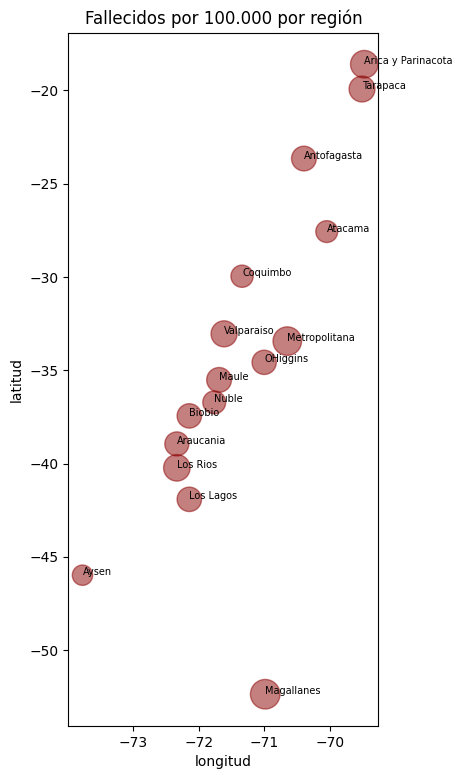

In [16]:
# Mapa de burbujas: fallecidos por 100.000 en cada región (posición de la tabla UID)
fig, ax = plt.subplots(figsize=(4, 9))
ax.scatter(p2['long'], p2['lat'], s=p2['fallecidos_x100k'], alpha=0.5, color='darkred')
for nombre, fila in p2.iterrows():
    ax.annotate(nombre.replace('Chile · ', ''), (fila['long'], fila['lat']), fontsize=7)
ax.set_title('Fallecidos por 100.000 por región')
ax.set_xlabel('longitud')
ax.set_ylabel('latitud')
plt.show()

**Interpretación:** desde junio de 2020, **Magallanes (453)** y **Metropolitana (423)** tienen la mayor mortalidad por 100.000; **Biobío queda 10.º de 16 (309)**. Para 11 de las 16 regiones la ola con más casos por 100.000 fue **ómicron (ola 3)**; en el norte (Tarapacá, Antofagasta, Atacama, Coquimbo) y Valparaíso fue la **ola 4** (segundo semestre de 2022).

### P4 · ¿Qué tan confiables son los datos de cada país?
Índice de calidad de `02_calidad` (100 = sin problemas detectados).

Mediana mundial del índice: 99.8


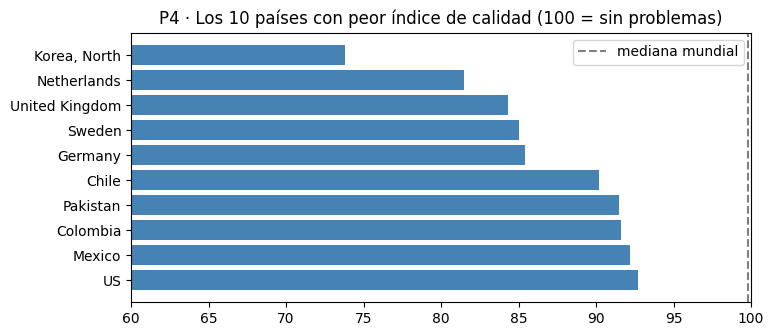

,pais,indice_calidad,causa_principal
91,"Korea, North",73.8,fallecidos > casos
125,Netherlands,81.5,difiere de la serie
186,United Kingdom,84.3,difiere de la serie
168,Sweden,85.0,difiere de la serie
65,Germany,85.4,difiere de la serie
35,Chile,90.2,difiere de la serie
133,Pakistan,91.5,difiere de la serie
37,Colombia,91.6,difiere de la serie
114,Mexico,92.2,difiere de la serie
182,US,92.7,difiere de la serie


In [17]:
calidad = pd.read_parquet(os.path.join(LIMPIOS, 'calidad_por_pais.parquet'))
causas = {'dias_acum_baja': 'acumulado que baja', 'picos_rezago': 'picos por rezago',
          'dias_fallec_mayor': 'fallecidos > casos', 'dias_difiere_serie': 'difiere de la serie',
          'dias_sin_reporte': 'días sin reporte'}
calidad['causa_principal'] = calidad[list(causas.keys())].idxmax(axis=1).replace(causas)
peores = calidad[~calidad['pais'].isin(entidades_especiales)].sort_values('indice_calidad').head(10)
print('Mediana mundial del índice:', calidad['indice_calidad'].median())

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(peores['pais'], peores['indice_calidad'], color='steelblue')
ax.axvline(calidad['indice_calidad'].median(), color='gray', linestyle='--', label='mediana mundial')
ax.invert_yaxis()
ax.set_xlim(60, 100)
ax.set_title('P4 · Los 10 países con peor índice de calidad (100 = sin problemas)')
ax.legend()
plt.show()
peores[['pais', 'indice_calidad', 'causa_principal']]

**Interpretación:** la mediana mundial del índice es **99,8**: la mayoría de los países tiene pocos problemas detectados. El peor es **Corea del Norte (73,8)**, que informa más fallecidos que casos durante 300 días. Le siguen países europeos (Países Bajos, Reino Unido, Suecia, Alemania) cuyo problema principal es que sus reportes diarios **difieren de la serie** que JHU corrigió después. **Chile (90,2) es el 6.º peor** por la misma causa (el rezago de junio de 2020). **Decisión:** Corea del Norte queda fuera de las tasas y comparaciones (P7 usa índice ≥ 80); los demás problemas se marcan, no se corrigen.

### P6 · ¿Se podía anticipar la ola de ómicron en Chile?

Inicio de la ola de ómicron (incidencia > 100): 2022-01-09
Días de anticipación de la alerta: 5
Primer día con alerta activa: 2022-01-04
                       MAE  MAPE %
media_movil          579.0    26.4
tendencia            696.0    32.6
crecimiento_semanal  663.0    30.9


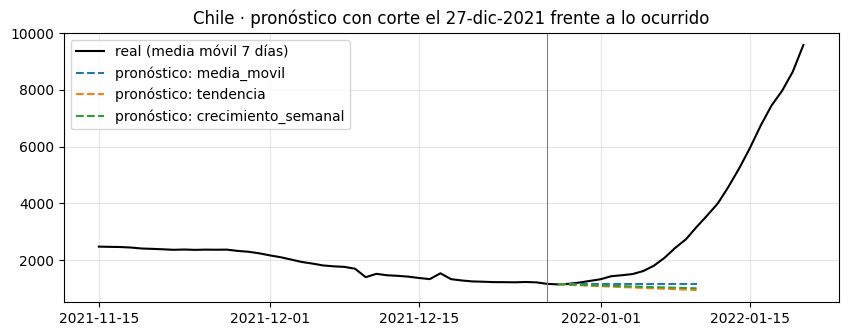

In [18]:
ola_omicron = olas_chile[olas_chile['inicio'] >= '2021-12-01'].iloc[0]
print('Inicio de la ola de ómicron (incidencia > 100):', ola_omicron['inicio'].date())
print('Días de anticipación de la alerta:', tabla_alerta.loc[ola_omicron.name, 'dias_de_anticipacion'])
primera = historia[(historia.index >= '2021-12-01') & historia]
print('Primer día con alerta activa:', primera.index.min().date())

p6, err6 = comparar('Chile', '2021-12-27')
print(err6)

fig, ax = plt.subplots(figsize=(10, 3.5))
hist = serie[(serie['territorio'] == 'Chile') & (serie['fecha'] >= '2021-11-15') & (serie['fecha'] <= '2022-01-20')]
ax.plot(hist['fecha'], hist['casos_mm7'], color='black', label='real (media móvil 7 días)')
for modelo in MODELOS:
    ax.plot(p6['fecha'], p6[modelo], linestyle='--', label=f'pronóstico: {modelo}')
ax.axvline(pd.Timestamp('2021-12-27'), color='gray', linewidth=0.8)
ax.set_title('Chile · pronóstico con corte el 27-dic-2021 frente a lo ocurrido')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**Interpretación:** **en parte.** La alerta se encendió el **4-ene-2022**, **5 días antes** de que la incidencia pasara de 100 por 100.000 (9-ene). Pero los pronósticos con corte el 27-dic-2021 **no vieron venir la ola**: los tres modelos proyectaron casos estables o a la baja (errores de 26 % a 33 %), porque a fines de diciembre los casos todavía venían bajando. Con datos de casos solamente, ómicron se detecta cuando ya empezó; para anticiparla hacían falta otras señales (secuenciación de variantes, lo que ya pasaba en otros países).

## 5 · Guardar la serie para el tablero

In [19]:
serie.to_parquet(os.path.join(LIMPIOS, 'serie_territorio.parquet'), index=False)
print('Guardado:', os.path.join(LIMPIOS, 'serie_territorio.parquet'),
      round(os.path.getsize(os.path.join(LIMPIOS, 'serie_territorio.parquet')) / 1e6, 1), 'MB')

Guardado: /content/drive/MyDrive/proyecto-gestion-datos-2026/data/clean/serie_territorio.parquet 4.7 MB
